<a href="https://colab.research.google.com/github/Yireh111/MachineLearning/blob/main/Unidad%20IV/Unidad_4_Pacientes_KMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Segmentación de pacientes en hábitos relacionados con la salud cardiovascular con K-Means**

Unidad 4 – Aprendizaje no supervisado

Aplicar K-Means y Análisis de Componentes Principales (PCA) para identificar patrones y agrupamientos de pacientes según sus características clínicas, demográficas y hábitos relacionados con la salud cardiovascular.

Integrantes:
- Gael Yireh Benitez Medina
- Angel Zaid Gamiz Reyes
- Jaime Alejandro Frayre Salazar
- Josue Ulises Rios Garcia

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

In [ ]:
ARCHIVO = "patient_dataset.csv"
if not os.path.exists(ARCHIVO):
    try:
        from google.colab import files
        print("Sube el archivo patient_dataset.csv")
        subido = files.upload()
        ARCHIVO = list(subido.keys())[0]
    except ImportError:
        raise FileNotFoundError("Coloca patient_dataset.csv en la misma carpeta del notebook.")

df = pd.read_csv(ARCHIVO)
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (6000, 16)


,age,gender,chest_pain_type,blood_pressure,cholesterol,max_heart_rate,exercise_angina,plasma_glucose,skin_thickness,insulin,bmi,diabetes_pedigree,hypertension,heart_disease,residence_type,smoking_status
0,24,1.0,4,250,139,212,0,108.0,33.0,109.0,37.999303,0.480277,1,1,Urban,Smoker
1,29,0.0,4,132,187,147,0,202.0,42.0,NaN,25.588346,0.283986,1,1,Urban,Unknown
2,46,0.0,3,271,185,193,0,149.0,43.0,102.0,37.892029,2.472309,1,0,Rural,Non-Smoker
3,73,NaN,2,102,200,125,0,105.0,77.0,165.0,18.660241,1.472052,0,1,Rural,Smoker
4,49,1.0,3,91,163,192,0,162.0,31.0,170.0,12.767980,0.537627,1,1,Rural,Smoker


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                6000 non-null   int64  
 1   gender             5528 non-null   float64
 2   chest_pain_type    6000 non-null   int64  
 3   blood_pressure     6000 non-null   int64  
 4   cholesterol        6000 non-null   int64  
 5   max_heart_rate     6000 non-null   int64  
 6   exercise_angina    6000 non-null   int64  
 7   plasma_glucose     5391 non-null   float64
 8   skin_thickness     5386 non-null   float64
 9   insulin            5432 non-null   float64
 10  bmi                6000 non-null   float64
 11  diabetes_pedigree  6000 non-null   float64
 12  hypertension       6000 non-null   int64  
 13  heart_disease      6000 non-null   int64  
 14  residence_type     5545 non-null   object 
 15  smoking_status     6000 non-null   object 
dtypes: float64(6), int64(8),

In [ ]:
# Estadísticos descriptivos (numéricas) y valores faltantes
display(df.describe().T.round(2))

faltantes = pd.DataFrame({"faltantes": df.isna().sum(), "% faltante": (df.isna().mean()*100).round(2)})
display(faltantes[faltantes.faltantes > 0])

,count,mean,std,min,25%,50%,75%,max
age,6000.0,53.66,21.02,18.00,36.00,53.00,72.00,90.0
gender,5528.0,0.50,0.50,0.00,0.00,0.00,1.00,1.0
chest_pain_type,6000.0,2.52,1.12,1.00,2.00,3.00,4.00,4.0
blood_pressure,6000.0,134.28,48.30,0.00,109.00,135.00,161.00,300.0
cholesterol,6000.0,209.84,52.84,120.00,164.00,210.00,257.00,300.0
max_heart_rate,6000.0,145.00,43.58,70.00,108.00,144.00,183.00,220.0
exercise_angina,6000.0,0.50,0.50,0.00,0.00,1.00,1.00,1.0
plasma_glucose,5391.0,161.12,52.43,70.00,116.00,162.00,206.00,250.0
skin_thickness,5386.0,59.96,23.26,20.00,40.00,60.00,80.00,100.0
insulin,5432.0,129.60,29.21,80.00,105.00,129.00,155.00,180.0


,faltantes,% faltante
gender,472,7.87
plasma_glucose,609,10.15
skin_thickness,614,10.23
insulin,568,9.47
residence_type,455,7.58


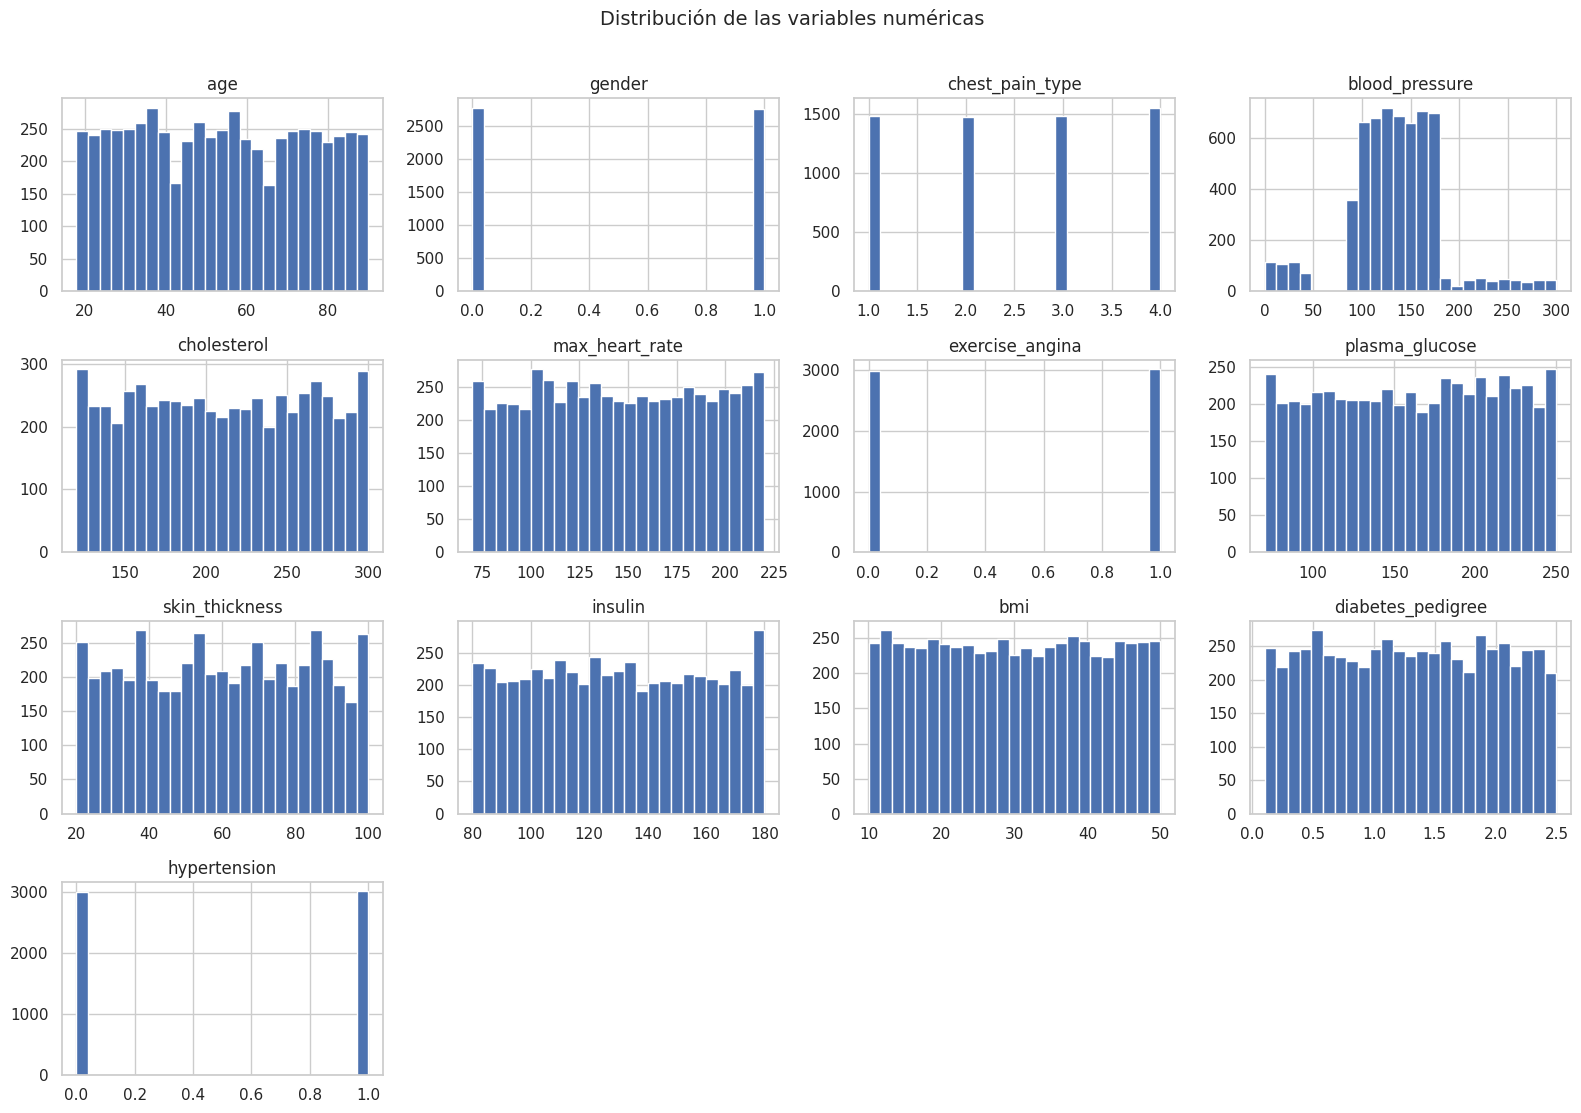

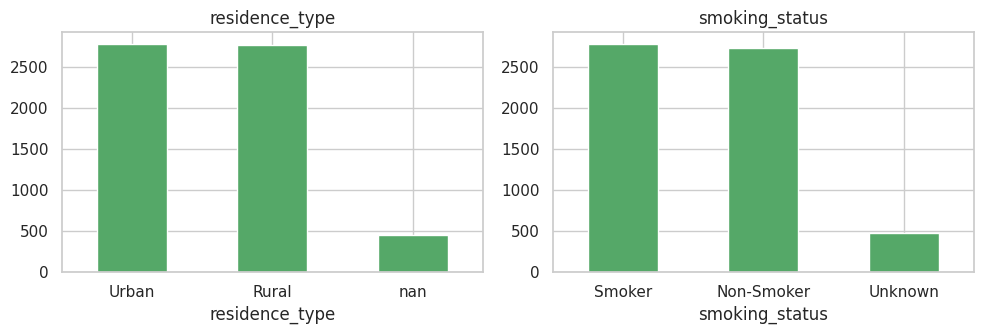

In [ ]:
# Distribución de variables numéricas
num_cols = df.select_dtypes(include="number").columns.drop("heart_disease")
df[num_cols].hist(bins=25, figsize=(16, 11), color="#4C72B0", edgecolor="white")
plt.suptitle("Distribución de las variables numéricas", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

# Variables categóricas
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, c in zip(ax, ["residence_type", "smoking_status"]):
    df[c].value_counts(dropna=False).plot(kind="bar", ax=a, color="#55A868")
    a.set_title(c); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

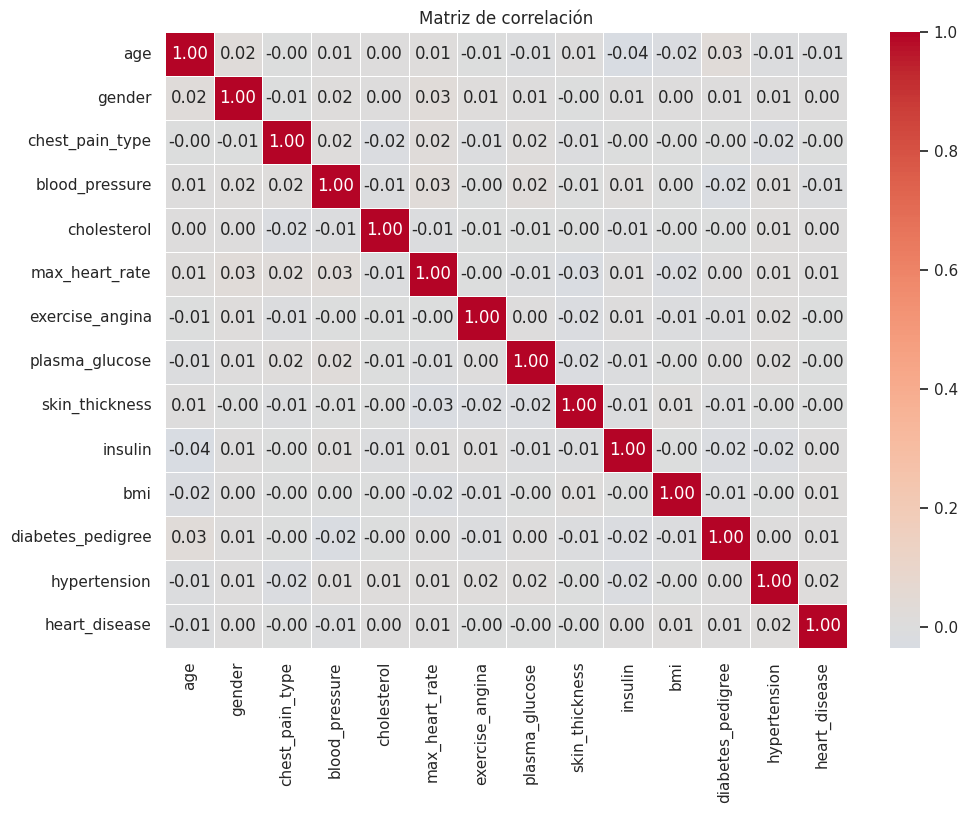

In [ ]:
# Matriz de correlación
plt.figure(figsize=(11, 8))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Matriz de correlación")
plt.show()

**Observaciones**
- El dataset tiene 6,000 pacientes y 16 variables.
- Hay valores faltantes en gender, plasma_glucose, skin_thickness, insulin y residence_type; deben tratarse antes de usar PCA/K-Means, que no admiten NaN.
- Las variables tienen escalas muy distintas (colesterol en cientos, diabetes_pedigree en unidades), por lo que es indispensable estandarizar.
- Las correlaciones entre variables son prácticamente nulas, lo que anticipa que la estructura de clusters será débil.

##**Descripción de las variables**

| Variable | Tipo | Descripción |
|---|---|---|
| age | numérica (int) | Edad del paciente en años |
| gender | numérica (float) | Sexo (0 = mujer, 1 = hombre) |
| chest_pain_type | numérica (int) | Tipo de dolor torácico (codificado) |
| blood_pressure | numérica (int) | Presión arterial en reposo (mm Hg) |
| cholesterol | numérica (int) | Colesterol sérico (mg/dl) |
| max_heart_rate | numérica (int) | Frecuencia cardíaca máxima alcanzada |
| exercise_angina | numérica (int) | Angina inducida por ejercicio (0 = No, 1 = Sí) |
| plasma_glucose | numérica (float) | Glucosa en plasma |
| skin_thickness | numérica (float) | Espesor del pliegue cutáneo (mm) |
| insulin | numérica (float) | Nivel de insulina |
| bmi | numérica (float) | Índice de masa corporal |
| diabetes_pedigree | numérica (float) | Función de historial familiar de diabetes |
| hypertension | numérica (int) | Hipertensión (0 = No, 1 = Sí) |
| heart_disease | numérica (int) | Enfermedad cardíaca (0 = No, 1 = Sí). **No se usa en el clustering** |
| residence_type | categórica | Tipo de residencia |
| smoking_status | categórica | Estado de tabaquismo |

## **Estandarización**

- Valores inválidos: hay presiones arteriales de 0 mm Hg (imposibles); se tratan como faltantes.
- Valores faltantes: numéricas → mediana; categóricas → moda.
- Categóricas: residence_type y smoking_status se codifican con one-hot.
- heart_disease se excluye de las variables de entrada (se usará después solo para validar los clusters).
- Estandarización: StandardScaler (media 0, desviación estándar 1), necesaria porque PCA y K-Means dependen de distancias/varianzas.

In [ ]:
data = df.copy()

# Calidad de datos: presión arterial = 0 mm Hg es fisiológicamente imposible -> se trata como faltante
print("Valores de presión arterial = 0:", int((data["blood_pressure"] <= 0).sum()))
data.loc[data["blood_pressure"] <= 0, "blood_pressure"] = np.nan

# Imputación
for c in data.select_dtypes(include="number").columns:
    data[c] = data[c].fillna(data[c].median())
for c in ["residence_type", "smoking_status"]:
    data[c] = data[c].fillna(data[c].mode()[0])

# Variable objetivo de validación (NO se usa para agrupar)
heart_disease = data["heart_disease"].copy()

# Matriz de características para el PCA exploratorio
X_all = pd.get_dummies(data.drop(columns="heart_disease"),
                       columns=["residence_type", "smoking_status"], dtype=int)
print("Valores faltantes tras imputar:", int(data.isna().sum().sum()))
print("Variables de entrada:", X_all.shape[1])

scaler_all = StandardScaler()
Z_all = scaler_all.fit_transform(X_all)

Valores de presión arterial = 0: 11
Valores faltantes tras imputar: 0
Variables de entrada: 18


## **PCA exploratorio con todas las variables**

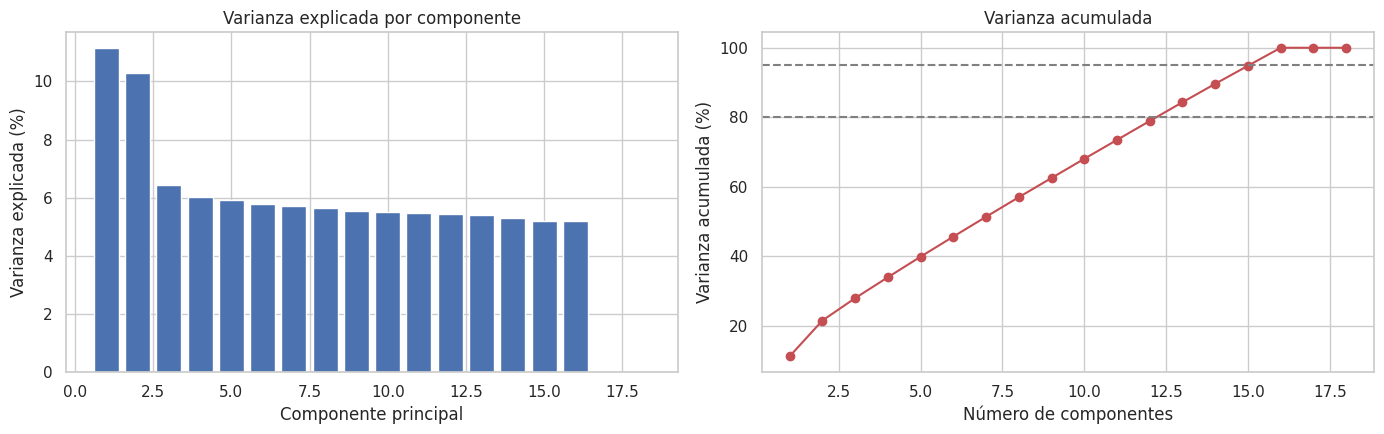

Componentes para >= 80% de varianza: 13
Componentes para >= 95% de varianza: 16 de 18


In [ ]:
pca_all = PCA(random_state=RANDOM_STATE).fit(Z_all)
var_exp = pca_all.explained_variance_ratio_
cum = np.cumsum(var_exp)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(range(1, len(var_exp)+1), var_exp*100, color="#4C72B0")
ax[0].set(xlabel="Componente principal", ylabel="Varianza explicada (%)", title="Varianza explicada por componente")
ax[1].plot(range(1, len(cum)+1), cum*100, marker="o", color="#C44E52")
ax[1].axhline(80, ls="--", color="gray"); ax[1].axhline(95, ls="--", color="gray")
ax[1].set(xlabel="Número de componentes", ylabel="Varianza acumulada (%)", title="Varianza acumulada")
plt.tight_layout(); plt.show()

print(f"Componentes para >= 80% de varianza: {np.argmax(cum >= .80)+1}")
print(f"Componentes para >= 95% de varianza: {np.argmax(cum >= .95)+1} de {len(cum)}")

## **Variables clínicas para el clustering y PCA**

El agrupamiento se hace exclusivamente con cuatro variables clínicas:
blood_pressure, cholesterol, plasma_glucose y max_heart_rate.

In [ ]:
features = ["blood_pressure", "cholesterol", "plasma_glucose", "max_heart_rate"]
X = data[features].copy()

scaler = StandardScaler()
Z = scaler.fit_transform(X)
Z_df = pd.DataFrame(Z, columns=features)

# PCA sobre las 4 variables seleccionadas
pca = PCA(random_state=RANDOM_STATE)
PC = pca.fit_transform(Z)
pc_cols = [f"PC{i+1}" for i in range(PC.shape[1])]

tabla_var = pd.DataFrame({
    "Componente": pc_cols,
    "Varianza explicada (%)": (pca.explained_variance_ratio_*100).round(2),
    "Varianza acumulada (%)": (np.cumsum(pca.explained_variance_ratio_)*100).round(2),
})
display(tabla_var)

loadings = pd.DataFrame(pca.components_.T, index=features, columns=pc_cols)
print("Cargas (loadings) de cada variable en los componentes:")
display(loadings.round(3))

,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,25.97,25.97
1,PC2,25.17,51.14
2,PC3,24.72,75.86
3,PC4,24.14,100.00


Cargas (loadings) de cada variable en los componentes:


,PC1,PC2,PC3,PC4
blood_pressure,0.637,0.149,0.400,0.642
cholesterol,-0.475,0.034,0.875,-0.082
plasma_glucose,0.219,0.866,0.044,-0.446
max_heart_rate,0.566,-0.475,0.268,-0.618


Con 4 variables y sin correlación entre ellas, cada componente explica cerca de 25% de la varianza. Se conservan los 4 componentes (que equivalen a rotar el espacio original) porque el clustering se hace sobre las variables estandarizadas y el PCA se usa sobre todo para visualizar (PC1–PC2 y PC3–PC4) e interpretar las variables mediante el biplot.

## **Número de clusters: método del codo y silhouette**

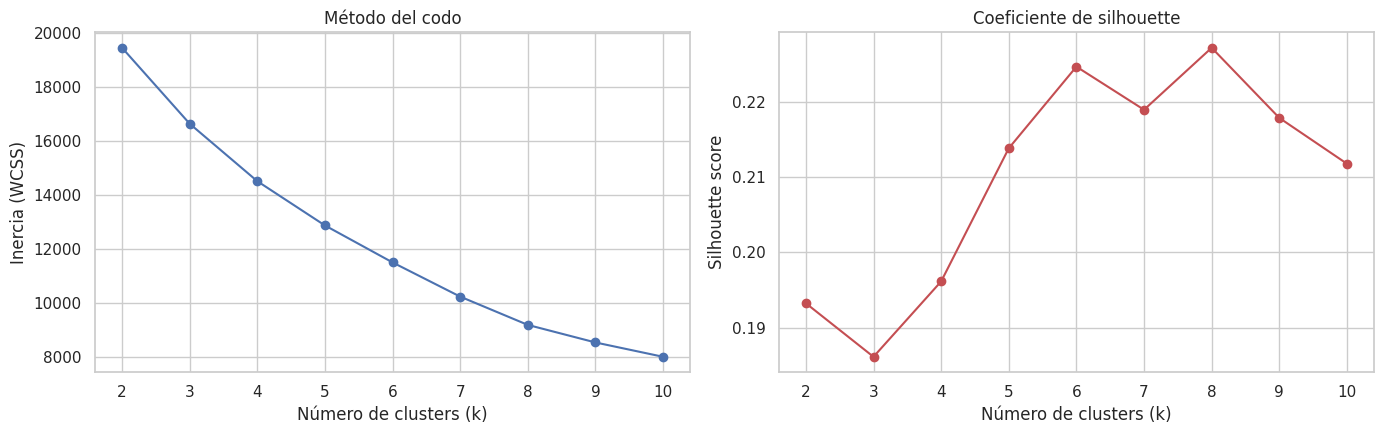

Tabla comparativa de inercia y silhouette por k:


,Inercia,Silhouette
k,,
2,19455.9479,0.1932
3,16639.3019,0.1861
4,14508.4687,0.1961
5,12867.4022,0.2138
6,11495.8201,0.2247
7,10227.2397,0.2190
8,9178.4319,0.2272
9,8527.5832,0.2179
10,7996.5333,0.2118


In [ ]:
K_RANGE = range(2, 11)
resultados = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    resultados.append({"k": k, "Inercia": km.inertia_,
                       "Silhouette": silhouette_score(Z, km.labels_)})
res = pd.DataFrame(resultados)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(res.k, res.Inercia, marker="o", color="#4C72B0")
ax[0].set(xlabel="Número de clusters (k)", ylabel="Inercia (WCSS)", title="Método del codo")
ax[1].plot(res.k, res.Silhouette, marker="o", color="#C44E52")
ax[1].set(xlabel="Número de clusters (k)", ylabel="Silhouette score", title="Coeficiente de silhouette")
for a in ax: a.set_xticks(list(K_RANGE))
plt.tight_layout(); plt.show()

print("Tabla comparativa de inercia y silhouette por k:")
display(res.round(4).set_index("k"))

Análisis de la selección de k

- Método del codo: la inercia baja de forma gradual y continua al aumentar k (de ≈19,456 con k=2 a ≈7,997 con k=10); no aparece un codo nítido. La mayor caída relativa ocurre entre k=2 y k=4, y después la curva se suaviza.
- Silhouette: todos los valores son bajos (≈0.19 a 0.23). El máximo está en k=8 (≈0.227), pero la diferencia frente a k=3 (≈0.186) es pequeña, y con 8 grupos la interpretación clínica sería poco práctica.
- Decisión: se usa k = 3, porque permite relacionar los clusters con los tres niveles de riesgo que pide el enunciado (bajo, medio y alto) y mantiene grupos de tamaño parecido y fáciles de interpretar. Se reconoce que los datos no presentan una estructura de clusters fuerte; los grupos obtenidos son una partición útil, pero no grupos naturalmente separados.

## **K-Means final y asignación de clusters**

In [ ]:
K = 3   # tres niveles de riesgo: bajo, medio y alto (ver justificación arriba)

km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z)

# Se reordenan las etiquetas según un puntaje de riesgo del centroide:
# suma de z de presión, colesterol y glucosa + |z| de la frecuencia cardíaca (valores anormales, altos o bajos)
centros_z = pd.DataFrame(km.cluster_centers_, columns=features)
score = (centros_z[["blood_pressure", "cholesterol", "plasma_glucose"]].sum(axis=1)
         + centros_z["max_heart_rate"].abs())
orden = score.sort_values().index.tolist()          # de menor a mayor riesgo
mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
nombres = {0: "Riesgo bajo", 1: "Riesgo medio", 2: "Riesgo alto"}

labels = np.array([mapa[l] for l in km.labels_])
data["cluster"] = labels
data["perfil"] = data["cluster"].map(nombres)
print("Silhouette del modelo final:", round(silhouette_score(Z, labels), 4))
print("Inercia del modelo final:", round(km.inertia_, 1))
print()
print(data["perfil"].value_counts().reindex(nombres.values()))

Silhouette del modelo final: 0.1861
Inercia del modelo final: 16639.3

perfil
Riesgo bajo     1849
Riesgo medio    2291
Riesgo alto     1860
Name: count, dtype: int64


## **Visualización de los clusters**

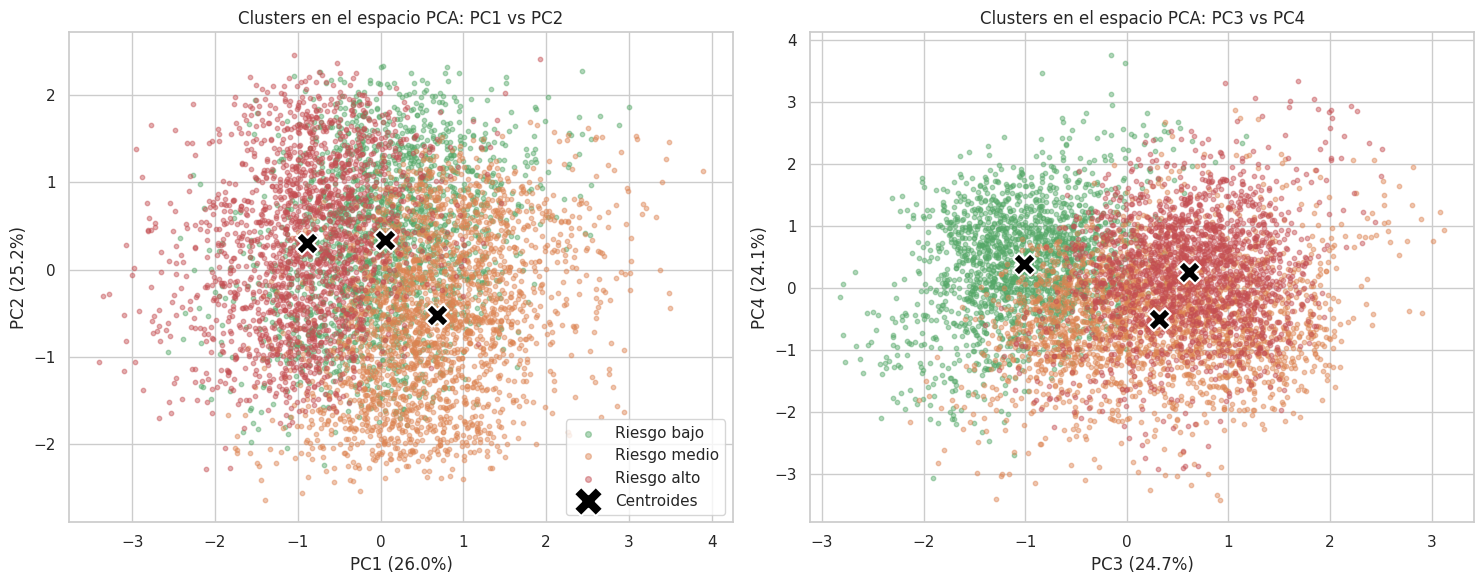

In [ ]:
colores = {0: "#55A868", 1: "#DD8452", 2: "#C44E52"}
centros_pc = pca.transform(km.cluster_centers_)
centros_pc = pd.DataFrame(centros_pc, columns=pc_cols).rename(index=mapa).sort_index()

def scatter_pc(ax, a, b):
    for c in range(K):
        m = labels == c
        ax.scatter(PC[m, a], PC[m, b], s=10, alpha=.45, color=colores[c], label=nombres[c])
    ax.scatter(centros_pc.iloc[:, a], centros_pc.iloc[:, b], marker="X", s=260,
               color="black", edgecolor="white", linewidth=1.5, label="Centroides", zorder=5)
    ax.set_xlabel(f"PC{a+1} ({pca.explained_variance_ratio_[a]*100:.1f}%)")
    ax.set_ylabel(f"PC{b+1} ({pca.explained_variance_ratio_[b]*100:.1f}%)")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
scatter_pc(ax[0], 0, 1); ax[0].set_title("Clusters en el espacio PCA: PC1 vs PC2")
scatter_pc(ax[1], 2, 3); ax[1].set_title("Clusters en el espacio PCA: PC3 vs PC4")
ax[0].legend(markerscale=1.3)
plt.tight_layout(); plt.show()

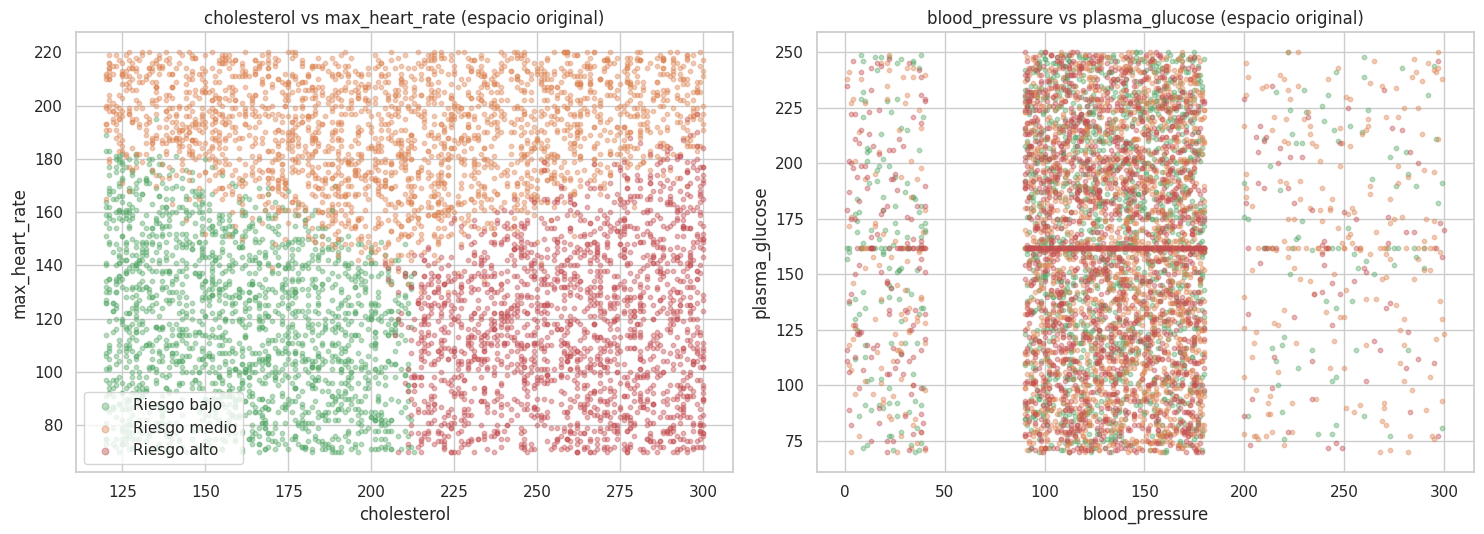

In [ ]:
# Espacio original (pares de variables clínicas, sin estandarizar)
pares = [("cholesterol", "max_heart_rate"), ("blood_pressure", "plasma_glucose")]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, (x, y) in zip(ax, pares):
    for c in range(K):
        m = data.cluster == c
        a.scatter(data.loc[m, x], data.loc[m, y], s=10, alpha=.4, color=colores[c], label=nombres[c])
    a.set_xlabel(x); a.set_ylabel(y); a.set_title(f"{x} vs {y} (espacio original)")
ax[0].legend(markerscale=1.5)
plt.tight_layout(); plt.show()

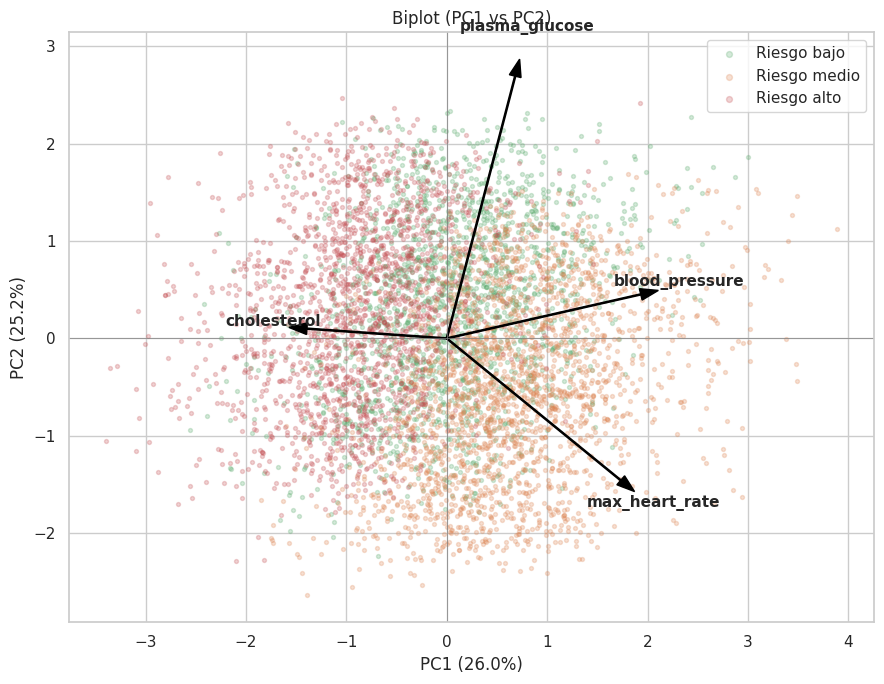

In [ ]:
# Biplot PC1 vs PC2: observaciones + vectores de las variables
fig, ax = plt.subplots(figsize=(9, 7))
for c in range(K):
    m = labels == c
    ax.scatter(PC[m, 0], PC[m, 1], s=8, alpha=.25, color=colores[c], label=nombres[c])
escala = np.abs(PC[:, :2]).max() * 0.85
for var in features:
    x, y = loadings.loc[var, "PC1"] * escala, loadings.loc[var, "PC2"] * escala
    ax.arrow(0, 0, x, y, color="black", width=.012, head_width=.12, length_includes_head=True)
    ax.text(x*1.1, y*1.1, var, fontsize=11, weight="bold", ha="center")
ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Biplot (PC1 vs PC2)"); ax.legend(markerscale=1.5)
plt.tight_layout(); plt.show()

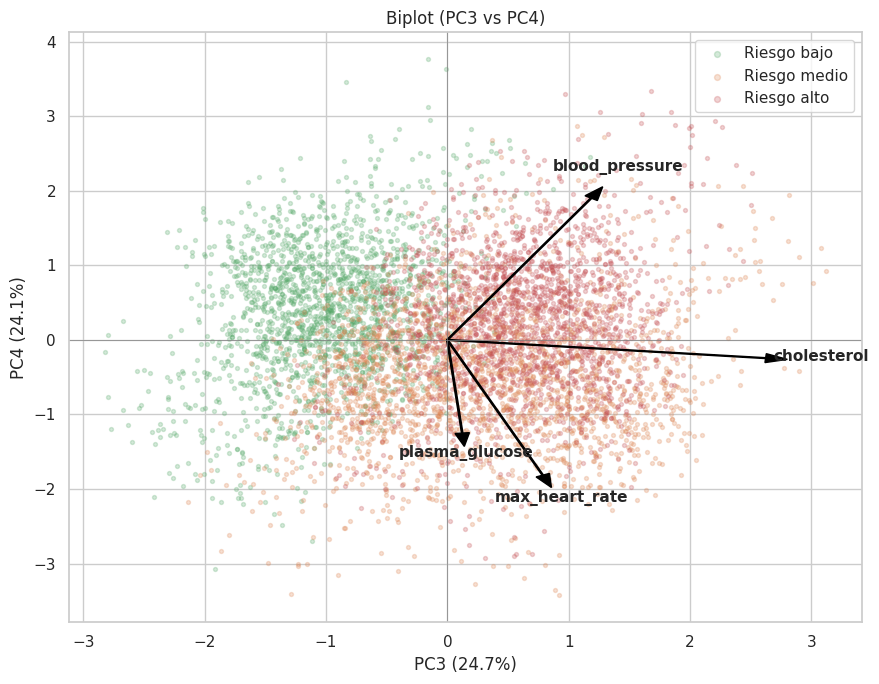

In [ ]:
# Biplot PC3 vs PC4
fig, ax = plt.subplots(figsize=(9, 7))
for c in range(K):
    m = labels == c
    ax.scatter(PC[m, 2], PC[m, 3], s=8, alpha=.25, color=colores[c], label=nombres[c])
escala = np.abs(PC[:, 2:4]).max() * 0.85
for var in features:
    x, y = loadings.loc[var, "PC3"] * escala, loadings.loc[var, "PC4"] * escala
    ax.arrow(0, 0, x, y, color="black", width=.012, head_width=.12, length_includes_head=True)
    ax.text(x*1.1, y*1.1, var, fontsize=11, weight="bold", ha="center")
ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
ax.set_xlabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)")
ax.set_ylabel(f"PC4 ({pca.explained_variance_ratio_[3]*100:.1f}%)")
ax.set_title("Biplot (PC3 vs PC4)"); ax.legend(markerscale=1.5)
plt.tight_layout(); plt.show()

**Lectura de las gráficas**

- En PC1 vs PC2 los tres grupos se traslapan bastante: no hay huecos entre ellos. Esto coincide con el silhouette bajo (≈0.19). Los centroides sí se ubican en zonas distintas.
- En PC3 vs PC4 la separación es más clara: PC3 está dominado por el colesterol (carga ≈0.88), por lo que los pacientes de colesterol bajo se agrupan a la izquierda y los de colesterol alto a la derecha.
- En el biplot, plasma_glucose domina PC2, mientras que blood_pressure y max_heart_rate pesan en PC1 y cholesterol en PC3. Los vectores están casi en ángulos rectos entre sí, lo que confirma que las cuatro variables son prácticamente independientes (sin correlación entre ellas).

## **Descripción e interpretación clínica de los clusters**

,blood_pressure,cholesterol,plasma_glucose,max_heart_rate,n pacientes,% del total
perfil,,,,,,
Riesgo bajo,130.9,160.6,165.6,117.2,1849,30.8
Riesgo medio,141.8,208.7,158.3,190.0,2291,38.2
Riesgo alto,129.1,260.2,160.4,117.2,1860,31.0


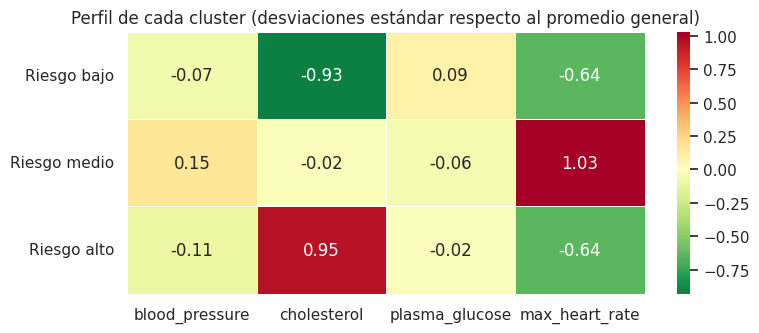

In [ ]:
# Promedio de cada variable clínica por cluster
perfil = (data.groupby("perfil")[features].mean()
          .reindex(nombres.values()).round(1))
perfil["n pacientes"] = data["perfil"].value_counts().reindex(nombres.values())
perfil["% del total"] = (perfil["n pacientes"] / len(data) * 100).round(1)
display(perfil)

# Desviación respecto al promedio general (en desviaciones estándar)
z_perfil = (data.groupby("perfil")[features].mean().reindex(nombres.values())
            - X.mean()) / X.std()
plt.figure(figsize=(8, 3.5))
sns.heatmap(z_perfil.round(2), annot=True, cmap="RdYlGn_r", center=0, fmt=".2f", linewidths=.5)
plt.title("Perfil de cada cluster (desviaciones estándar respecto al promedio general)")
plt.ylabel(""); plt.tight_layout(); plt.show()

In [ ]:
# Validación externa (variables NO usadas para agrupar)
validacion = data.groupby("perfil").agg(
    edad_prom=("age", "mean"),
    pct_hipertension=("hypertension", "mean"),
    pct_angina_ejercicio=("exercise_angina", "mean"),
    bmi_prom=("bmi", "mean"),
    pct_enfermedad_cardiaca=("heart_disease", "mean"),
).reindex(nombres.values())
for c in ["pct_hipertension", "pct_angina_ejercicio", "pct_enfermedad_cardiaca"]:
    validacion[c] = (validacion[c]*100).round(1)
display(validacion.round(1))

,edad_prom,pct_hipertension,pct_angina_ejercicio,bmi_prom,pct_enfermedad_cardiaca
perfil,,,,,
Riesgo bajo,53.6,49.8,50.9,30.2,49.2
Riesgo medio,53.8,51.3,50.0,29.9,50.3
Riesgo alto,53.5,49.1,50.1,29.7,49.8


### **Interpretación clínica de cada cluster**

Los valores corresponden a la ejecución con random_state=42. Para ubicarlos se usan referencias clínicas generales: presión ≥130/80 mm Hg se considera elevada, colesterol total <200 mg/dl es deseable y ≥240 mg/dl es alto, y glucosa en ayunas ≥126 mg/dl sugiere diabetes.

| Cluster | n (%) | Presión | Colesterol | Glucosa | FC máx. |
|---|---|---|---|---|---|
| **Riesgo bajo** | 1,849 (30.8%) | 130.9 | 160.6 | 165.6 | 117.2 |
| **Riesgo medio** | 2,291 (38.2%) | 141.8 | 208.7 | 158.3 | 190.0 |
| **Riesgo alto** | 1,860 (31.0%) | 129.1 | 260.2 | 160.4 | 117.2 |

**Cluster 0 – Riesgo bajo.** Tiene el colesterol más bajo (≈161 mg/dl, en rango deseable). La presión es la intermedia y la frecuencia cardíaca máxima es baja. Es el grupo más favorable, pero solo en términos relativos: su glucosa promedio es la más alta de los tres (≈166).

**Cluster 1 – Riesgo medio.** Colesterol en rango limítrofe (≈209 mg/dl) y la presión más alta (≈142 mm Hg, rango de hipertensión). Se distingue por una frecuencia cardíaca máxima muy alta (≈190 lpm), superior a lo esperado para la edad promedio del grupo (≈54 años, FC máx. teórica ≈166 lpm), lo que se considera anormal. Su glucosa es la más baja (≈158). Se clasifica como riesgo medio porque combina presión elevada y frecuencia anormal, pero con colesterol moderado. *Es una decisión de criterio: un clínico podría considerarlo de riesgo alto por su presión.*

**Cluster 2 – Riesgo alto.** Tiene el colesterol más elevado (≈260 mg/dl, por encima del umbral de 240), junto con glucosa alta (≈160) y frecuencia cardíaca máxima baja (≈117 lpm), que puede indicar menor capacidad de respuesta al esfuerzo. Es el perfil con hiperlipidemia clara.

**Observación general:** en los tres grupos la glucosa promedio (≈158–166) y la presión (≈129–142) están en rangos elevados. Las diferencias entre clusters se deben sobre todo al colesterol y a la frecuencia cardíaca máxima; la presión y la glucosa casi no los distinguen.

### **Validación con variables no utilizadas**

Se compararon los clusters con variables que **no** se usaron para agruparlos (edad, hipertensión, angina por ejercicio, IMC y `heart_disease`). Los valores son prácticamente iguales entre clusters (≈50% de enfermedad cardíaca en los tres, edad ≈54 años). Es decir, los clusters no se relacionan con la presencia de enfermedad cardíaca registrada en este dataset. Esto limita la lectura clínica: el "riesgo" asignado se basa únicamente en los valores de las cuatro variables, no en resultados observados.

## **Conclusiones**

1. Se exploró y preparó el dataset (6,000 pacientes): se imputaron valores faltantes, se trataron 11 presiones arteriales de 0 mm Hg como datos inválidos y se estandarizaron las variables con StandardScaler.
2. El PCA mostró que la varianza se reparte casi por igual entre los componentes (≈25% cada uno con las 4 variables clínicas; se necesitan 13 de 18 componentes para llegar a 80% con todas las variables). Las variables son casi independientes, por lo que no hay una reducción de dimensionalidad útil; el PCA sirvió principalmente para visualizar e interpretar variables mediante biplots.
3. El método del codo no mostró un codo claro y el silhouette fue bajo (≈0.19–0.23). Se eligió k = 3 por interpretabilidad (bajo, medio y alto riesgo).
4. K-Means generó tres perfiles: riesgo bajo (colesterol ≈161 mg/dl), riesgo medio (presión más alta y frecuencia cardíaca máxima ≈190 lpm) y riesgo alto (colesterol ≈260 mg/dl). Las diferencias se deben principalmente al colesterol y a la frecuencia cardíaca máxima.
5. Limitaciones: los grupos se traslapan, la estructura de clusters es débil y los clusters no difieren en la presencia de enfermedad cardíaca. Los resultados deben leerse como una segmentación exploratoria, no como una herramienta de diagnóstico. Los datos parecen sintéticos (distribuciones casi uniformes y sin correlaciones), lo cual explica gran parte de estos resultados.
6. Mejoras posibles: incluir más variables (edad, IMC, insulina), probar otros algoritmos (K-Medoids, GMM, jerárquico) y validar los grupos con datos clínicos reales.